# Homework 3 (due 26 October 2026 23:59:59)
### PHYS 440/540, Fall 2026

## Problem 1 (Geron; Chapter 9, Exercise 10)

Practice with faces.  Load the classic Olivetti faces dataset using the `sklearn.datasets.fetch_olivetti_faces() `function.  It contains 400 grayscale 64 × 64–pixel images that are flattened to a 1D vector of size 4,096. 40 different people were photographed (10 times each).

Use DESCR to learn about the data set.  Then print a listing of the target values.

Split the data into a training set and a test set (we should also make a validation set, but that's a topic for a future week!).  Make sure to use stratification.  Put 80% of the data into the training set (instead of the default of 75%).

Cluster the images using K-means.

Visualize your clusters.


## Problem 2

Use [datasets.make_blobs](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html#sklearn.datasets.make_blobs) to generate a fake sample of data.  It should have 100 data points each with 3 attributes/features where the objects are grouped into 4 clusters/groups.  Use `random_state=345679`.

Illustrate with a 2-D plot of two of the attributes.  

Show `X` as a 100x3 table of data.  

Print `X` again using Pandas and give each of the attributes a name.


[Possibly useful or of interest](https://medium.com/dunder-data/from-pandas-to-scikit-learn-a-new-exciting-workflow-e88e2271ef62)

---
#### Problem 1 Starter Code

In [2]:
import numpy as np
import matplotlib.pylab as plt
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\sarda_hx81cfu\scikit_learn_data


In [3]:
#Use DESCR to learn about the data set
print(olivetti.DESCR)

.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: https://cam-orl.co.uk/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position
    (with tolerance for some side movement).

**Data Set Characteristics:**

=================   =====================
Classes              

In [5]:
#View the "targets"
print(olivetti.target)

[ 0  0  0  0  0  0  0  0  0  0  1  1  1  1  1  1  1  1  1  1  2  2  2  2
  2  2  2  2  2  2  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4
  4  4  5  5  5  5  5  5  5  5  5  5  6  6  6  6  6  6  6  6  6  6  7  7
  7  7  7  7  7  7  7  7  8  8  8  8  8  8  8  8  8  8  9  9  9  9  9  9
  9  9  9  9 10 10 10 10 10 10 10 10 10 10 11 11 11 11 11 11 11 11 11 11
 12 12 12 12 12 12 12 12 12 12 13 13 13 13 13 13 13 13 13 13 14 14 14 14
 14 14 14 14 14 14 15 15 15 15 15 15 15 15 15 15 16 16 16 16 16 16 16 16
 16 16 17 17 17 17 17 17 17 17 17 17 18 18 18 18 18 18 18 18 18 18 19 19
 19 19 19 19 19 19 19 19 20 20 20 20 20 20 20 20 20 20 21 21 21 21 21 21
 21 21 21 21 22 22 22 22 22 22 22 22 22 22 23 23 23 23 23 23 23 23 23 23
 24 24 24 24 24 24 24 24 24 24 25 25 25 25 25 25 25 25 25 25 26 26 26 26
 26 26 26 26 26 26 27 27 27 27 27 27 27 27 27 27 28 28 28 28 28 28 28 28
 28 28 29 29 29 29 29 29 29 29 29 29 30 30 30 30 30 30 30 30 30 30 31 31
 31 31 31 31 31 31 31 31 32 32 32 32 32 32 32 32 32

In [6]:
# Split the data into training, validation, and test sets. Use stratification.
# 80% of the data goes into the training set; the remaining 20% is split evenly.

from sklearn.model_selection import train_test_split

X = olivetti.data
y = olivetti.target

Xtrain, Xtemp, ytrain, ytemp = train_test_split(
    X, y, stratify=y, test_size=0.20, random_state=42
)
Xvalid, Xtest, yvalid, ytest = train_test_split(
    Xtemp, ytemp, stratify=ytemp, test_size=0.50, random_state=42
)

In [7]:
print(Xtrain.shape,Xvalid.shape,Xtest.shape)

(320, 4096) (40, 4096) (40, 4096)


In [8]:
from sklearn.cluster import KMeans

k_range = range(4, 44, 4)
kmeans_scores = []
kmeans_per_k = []
for k in k_range:

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xtrain)
    kmeans_per_k.append(kmeans)
    
    score = kmeans.score(Xtrain)
    kmeans_scores.append(score)
    
    print("k={}, score={}".format(k, score))

k=4, score=-18004.1796875
k=8, score=-15892.2431640625
k=12, score=-14413.7578125
k=16, score=-13514.8505859375
k=20, score=-12589.51171875
k=24, score=-11842.2333984375
k=28, score=-11181.4169921875
k=32, score=-10487.5224609375
k=36, score=-9914.009765625
k=40, score=-9472.5595703125


In [9]:
best_index = np.argmax(kmeans_scores)
best_model = kmeans_per_k[best_index]
print(best_model,kmeans_scores[best_index])

KMeans(n_clusters=40, n_init=10, random_state=42) -9472.5595703125


Cluster 0


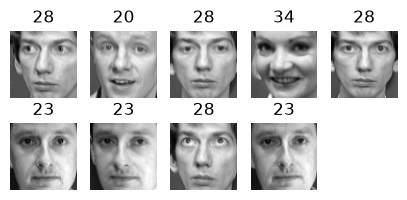

Cluster 1


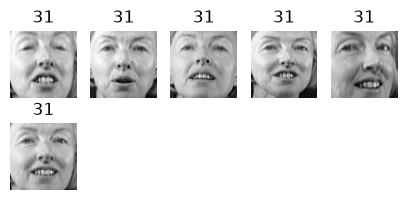

Cluster 2


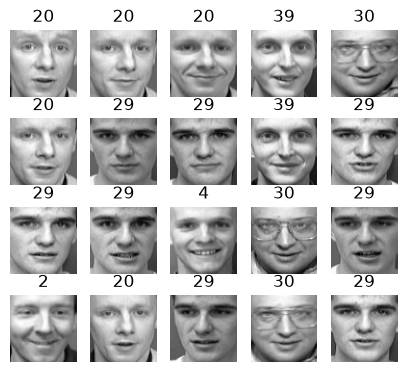

Cluster 3


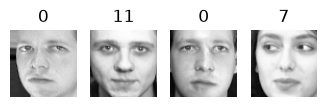

Cluster 4


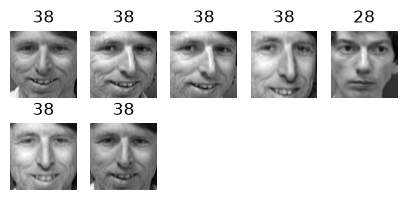

Cluster 5


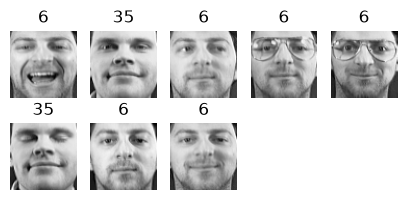

Cluster 6


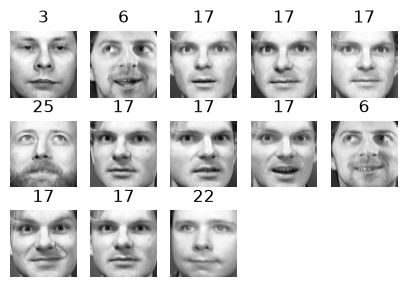

Cluster 7


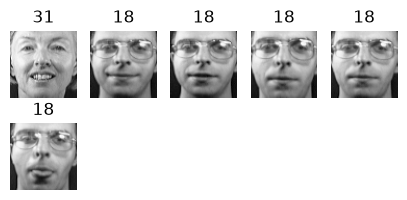

Cluster 8


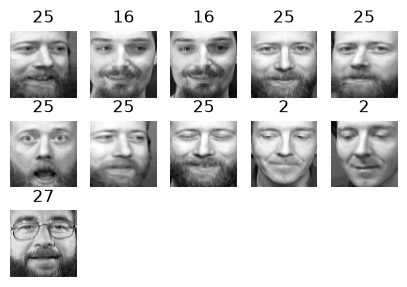

Cluster 9


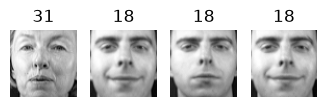

Cluster 10


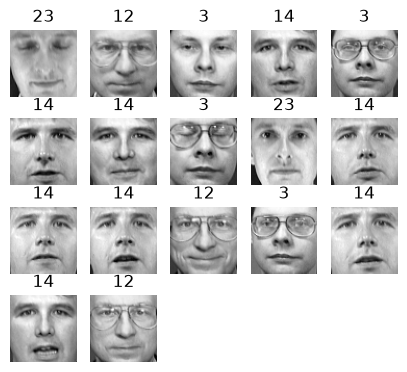

Cluster 11


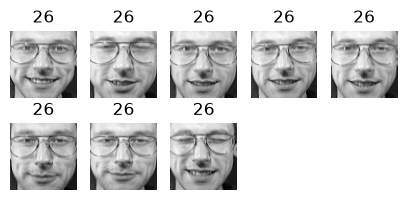

Cluster 12


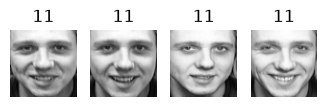

Cluster 13


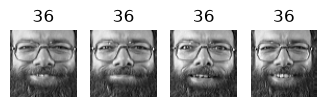

Cluster 14


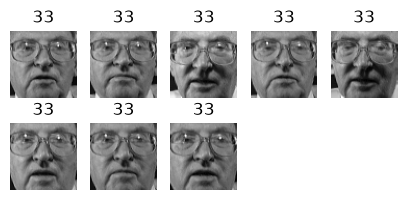

Cluster 15


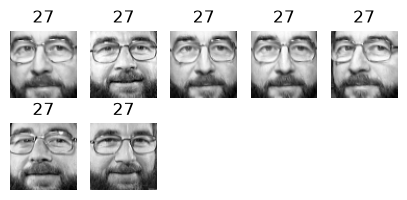

Cluster 16


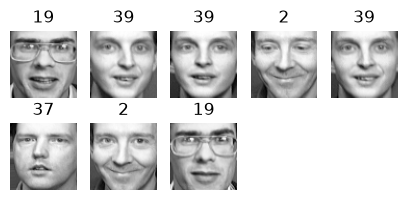

Cluster 17


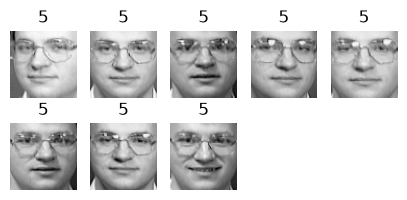

Cluster 18


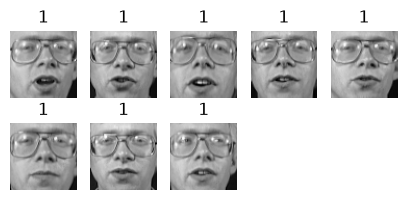

Cluster 19


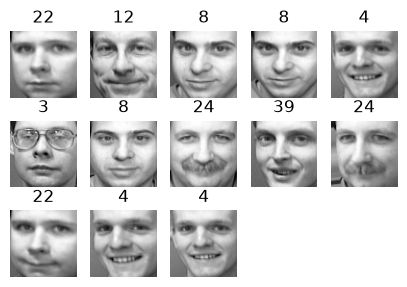

Cluster 20


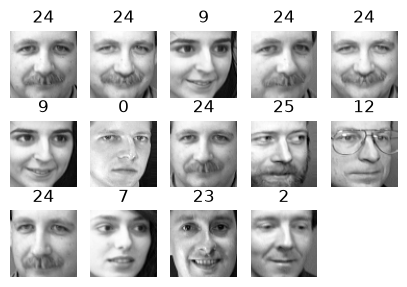

Cluster 21


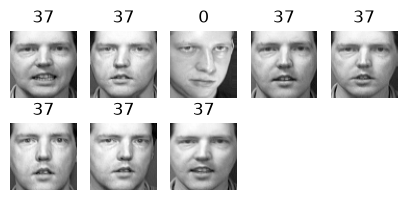

Cluster 22


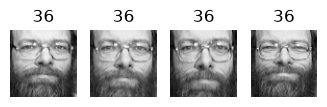

Cluster 23


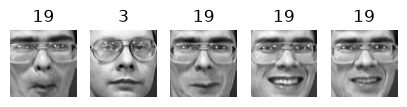

Cluster 24


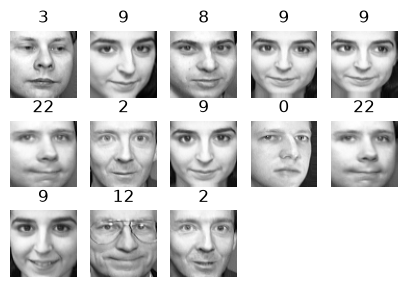

Cluster 25


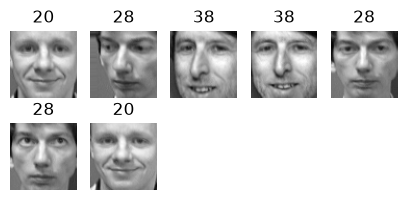

Cluster 26


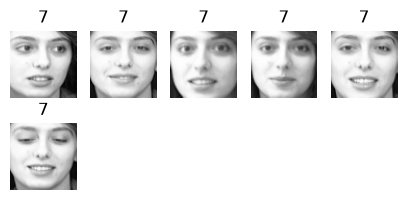

Cluster 27


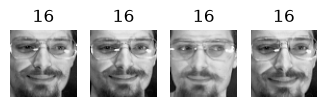

Cluster 28


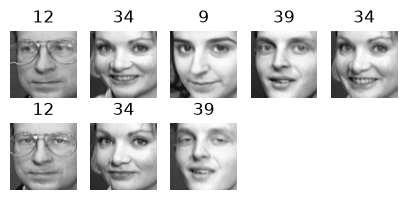

Cluster 29


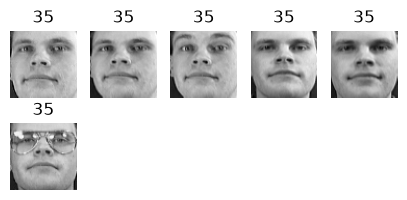

Cluster 30


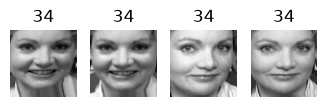

Cluster 31


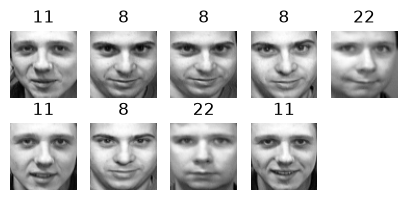

Cluster 32


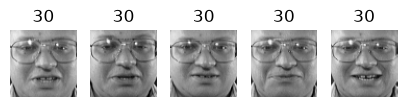

Cluster 33


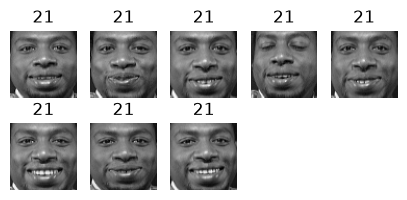

Cluster 34


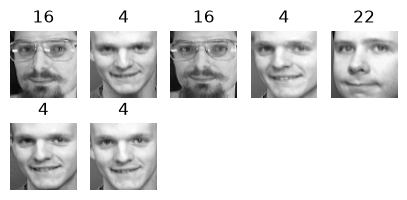

Cluster 35


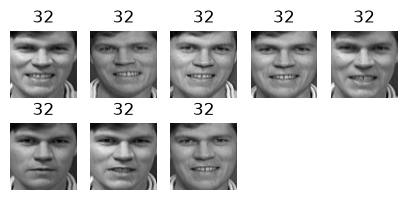

Cluster 36


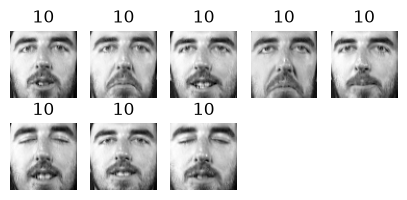

Cluster 37


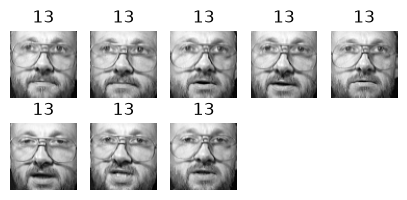

Cluster 38


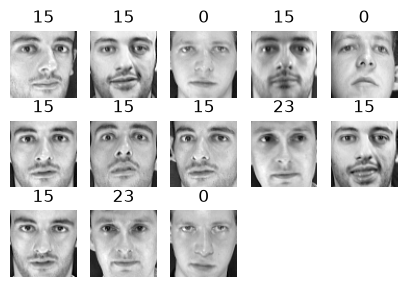

Cluster 39


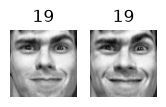

In [10]:
def plot_faces(faces, labels, n_cols=5):
    faces = faces.reshape(-1, 64, 64)
    n_rows = (len(faces) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows * 1.1))
    for index, (face, label) in enumerate(zip(faces, labels)):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face, cmap="gray", origin='upper')
        plt.axis("off")
        plt.title(label)
    plt.show()

for cluster_id in np.unique(best_model.labels_):
    print("Cluster", cluster_id)
    in_cluster = best_model.labels_==cluster_id
    faces = Xtrain[in_cluster]
    labels = ytrain[in_cluster]
    plot_faces(faces, labels)

---
#### Problem 2 Solution

Use [datasets.make_blobs](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html#sklearn.datasets.make_blobs) to generate a fake sample of data.  It should have 100 data points each with 3 attributes/features where the objects are grouped into 4 clusters.

Illustrate with a 2-D plot of two of the attributes.  Show `X` as a 100x3 table of data.  

In [11]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=100, n_features=3, centers=4, random_state=345679)

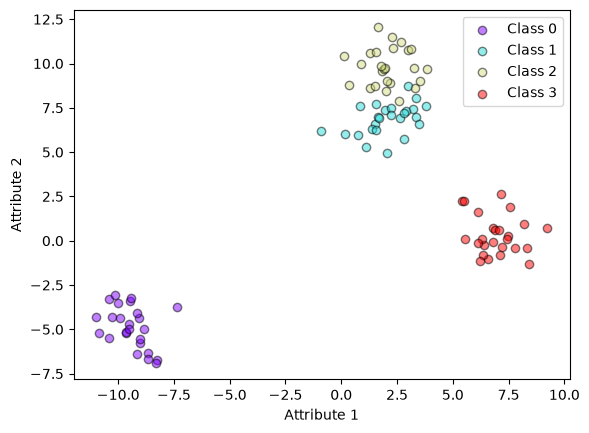

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

plt.figure() # setup plot

# Needed to plot clusters in color according to their labels
y_unique = np.unique(y)
colors = cm.rainbow(np.linspace(0.0, 1.0, y_unique.size))
for this_y, color in zip(y_unique, colors):
    this_X = X[y == this_y]
    # Plot the first two columns for all of the objects
    plt.scatter(this_X[:, 0], this_X[:, 1], c=color[np.newaxis, :],
                alpha=0.5, edgecolor='k', label="Class %s" % this_y)
    
plt.xlabel("Attribute 1")
plt.ylabel("Attribute 2")
plt.legend(loc="best")
plt.show()

In [13]:
print(X)

[[ -9.06978925  -4.34235675   7.34484086]
 [ -8.68511567  -6.33878873   7.29094368]
 [ -8.25545333  -6.71972214   6.47295812]
 [  2.06333324   4.95514963  -5.14290807]
 [  8.42954178  -1.32692832   8.03406797]
 [-10.40206553  -3.2635558    7.64099628]
 [-10.39400999  -5.50853176   6.56582261]
 [  3.00493927   8.70603107  -4.04637608]
 [  2.69054275  11.22790079   6.57046485]
 [  7.7906322   -0.42116364   8.0934302 ]
 [  5.42145785   2.22635528   9.51207484]
 [ -9.62837674  -5.2045148    7.37571844]
 [  5.53007106   0.10121852   7.23119819]
 [ -9.46709694  -3.41862531   9.07863798]
 [  1.64702059   6.96729328  -4.68308485]
 [  1.80940757   9.58392282   6.06415965]
 [  6.81826967   0.69439826   9.29411842]
 [  1.50502724   6.5815609   -5.42407186]
 [  7.46389229   0.2714582    9.55218764]
 [ -9.15880502  -4.07229452   8.36250455]
 [  6.59650447  -1.05894288   8.4896075 ]
 [  1.39786609   6.32716255  -3.92409714]
 [  3.198277     7.42583577  -5.52664897]
 [ -7.38499463  -3.76523557   8.05

Print `X` again in Pandas and give each of the attributes a name.

In [14]:
# Now with Pandas
import pandas as pd
dfX = pd.DataFrame(X)
dfX.columns = ["Attribute 1", "Attribute 2", "Attribute 3"]
print(dfX)

    Attribute 1  Attribute 2  Attribute 3
0     -9.069789    -4.342357     7.344841
1     -8.685116    -6.338789     7.290944
2     -8.255453    -6.719722     6.472958
3      2.063333     4.955150    -5.142908
4      8.429542    -1.326928     8.034068
..          ...          ...          ...
95     2.245246     7.103765    -5.819478
96     1.521199     8.708294     5.568196
97     6.115447    -0.139031     9.630557
98     7.430315     0.089472     9.952286
99   -10.019251    -3.485867     8.545517

[100 rows x 3 columns]
